ML environment ready

--- Dataset Inspection ---
Dataset shape: (442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

X shape: (442, 10)
y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.02

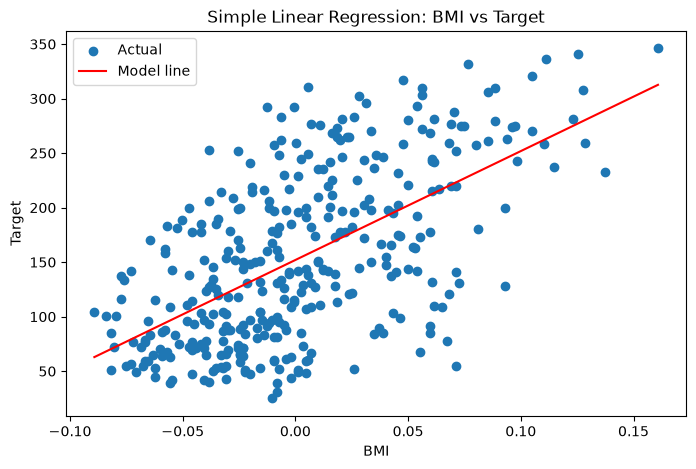


--- Multiple Linear Regression (All Features) ---
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]

--- Polynomial Regression (Degree 2, BMI) ---
First 5 predictions: [144.31652431 187.37853935 146.40224431 203.1205058  130.93222915]

--- Polynomial Degrees: Train MSE vs Test MSE ---
Degree  1 | Train MSE: 3854.11 | Test MSE: 4061.83
Degree  2 | Train MSE: 3849.33 | Test MSE: 4085.03
Degree  5 | Train MSE: 3823.76 | Test MSE: 4085.85
Degree 10 | Train MSE: 3815.59 | Test MSE: 3979.51

--- Gradient Descent From Scratch ---
Learned m, b: 2.0 0.02
Prediction at x=6: 11.99

--- Regularized Models (With StandardScaler) ---
Ridge R2: 0.454
Lasso R2: 0.456
ElasticNet R2: 0.459

--- Statsmodels OLS Statistical Summary ---
                            OLS Regression Results 

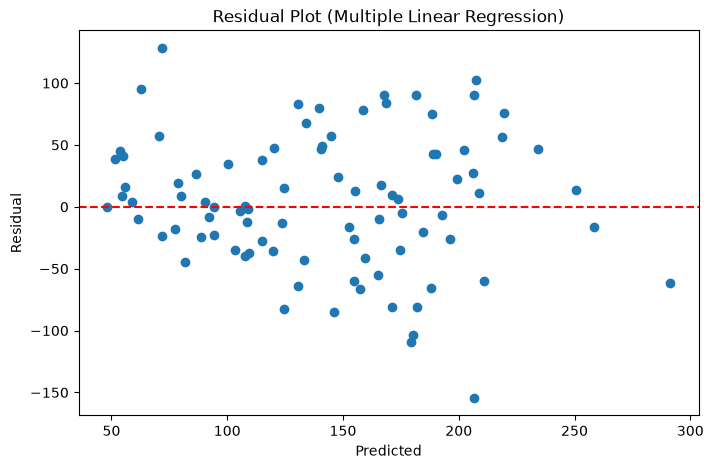


--- Final Multiple Regression Metrics ---
MAE: 42.794094679599944
MSE: 2900.1936284934814
RMSE: 53.85344583676593
R2: 0.4526027629719195


In [2]:
# ==========================================
# 1. Import Libraries & Verify Environment
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("ML environment ready")

# ==========================================
# 2. Load & Inspect Dataset
# ==========================================
dataset = load_diabetes(as_frame=True)
df = dataset.frame

print("\n--- Dataset Inspection ---")
print("Dataset shape:", df.shape)
print(df.head())

# ==========================================
# 3. Separate Features (X) and Target (y)
# ==========================================
X = df.drop(columns=["target"])
y = df["target"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

# ==========================================
# 4. Full Dataset Train-Test Split (80/20)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# ==========================================
# 5. Simple Linear Regression (Using 'bmi')
# ==========================================
X1 = X[["bmi"]]
Xtr, Xte, ytr, yte = train_test_split(
    X1, y, test_size=0.2, random_state=42
)

simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)

print("\n--- Simple Linear Regression (BMI) ---")
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)
print("First 5 predictions:", pred[:5])

# Plot Simple Linear Regression Line on Training Data
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)

plt.figure(figsize=(8, 5))
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
    Xtr["bmi"].values[order],
    pred_train[order],
    color="red",
    label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Target")
plt.title("Simple Linear Regression: BMI vs Target")
plt.legend()
plt.show()

# ==========================================
# 6. Multiple Linear Regression (All 10 Features)
# ==========================================
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)

print("\n--- Multiple Linear Regression (All Features) ---")
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])

# ==========================================
# 7. Polynomial Regression (Degree = 2 on 'bmi')
# ==========================================
poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly.fit(X_train[["bmi"]], y_train)
poly_pred = poly.predict(X_test[["bmi"]])

print("\n--- Polynomial Regression (Degree 2, BMI) ---")
print("First 5 predictions:", poly_pred[:5])

# ==========================================
# 8. Overfitting Check Across Polynomial Degrees
# ==========================================
print("\n--- Polynomial Degrees: Train MSE vs Test MSE ---")
for degree in (1, 2, 5, 10):
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )
    model.fit(X_train[["bmi"]], y_train)
    tr = model.predict(X_train[["bmi"]])
    te = model.predict(X_test[["bmi"]])
    print(
        f"Degree {degree:2d} | Train MSE: {mean_squared_error(y_train, tr):.2f} | Test MSE: {mean_squared_error(y_test, te):.2f}"
    )

# ==========================================
# 9. Gradient Descent From Scratch (Demo)
# ==========================================
x = np.array((1, 2, 3, 4, 5), dtype=float)
y_demo = np.array((2, 4, 6, 8, 10), dtype=float)
m, b = 0.0, 0.0
lr = 0.01

for epoch in range(1000):
    yhat = m * x + b
    dm = (-2 / len(x)) * np.sum(x * (y_demo - yhat))
    db = (-2 / len(x)) * np.sum(y_demo - yhat)
    m -= lr * dm
    b -= lr * db

print("\n--- Gradient Descent From Scratch ---")
print("Learned m, b:", round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m * 6 + b, 2))

# ==========================================
# 10. Regularized Models (Ridge, Lasso, ElasticNet)
# ==========================================
print("\n--- Regularized Models (With StandardScaler) ---")
models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}

for name, alg in models.items():
    pipe = make_pipeline(StandardScaler(), alg)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(name, "R2:", round(r2_score(y_test, p), 3))

# ==========================================
# 11. Statistical Inference (Statsmodels OLS)
# ==========================================
print("\n--- Statsmodels OLS Statistical Summary ---")
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print(ols.summary())

# ==========================================
# 12. Residual Plot (Multiple Regression)
# ==========================================
residuals = y_test - pred_multi

plt.figure(figsize=(8, 5))
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot (Multiple Linear Regression)")
plt.show()

# ==========================================
# 13. Full Evaluation Metrics (MAE, MSE, RMSE, R2)
# ==========================================
mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_multi)

print("\n--- Final Multiple Regression Metrics ---")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)
